# FactoryPulse — executed Phase 1 data evidence

This notebook reads the original research CSV files and the actual FactoryPulse MySQL latest-reading view. It performs **no database writes**. CSV research and operational telemetry remain distinct sources. No entered statistical summaries, missing-value imputation or automatic duplicate deletion are used.

Run from the project virtual environment. Set `FACTORYPULSE_DATASET_ROOT` if the original CSV folder differs. MySQL uses the backend's existing local environment configuration; connection strings and credentials are never displayed. Saved results are snapshots, not live reports.

In [1]:
from pathlib import Path
import sys, json, datetime as dt
ROOT = Path.cwd() if (Path.cwd() / "api_server").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.phase1_evidence import research_sources, quality_summary, numeric_summary, mysql_snapshot, live_statistics, reconciliation
executed_at = dt.datetime.now(dt.timezone.utc).isoformat()
print("Execution UTC:", executed_at)
print("pandas", pd.__version__, "numpy", np.__version__)
plt.rcParams.update({"figure.figsize": (10,4), "axes.spines.top":False,"axes.spines.right":False})

Execution UTC: 2026-11-03T05:21:17.265783+00:00
pandas 3.1.0 numpy 2.5.4


## 1. Original source manifest and measured quality
SHA-256 identifies exact input files. Duplicate value rows are reported and retained: identical readings do not establish duplicated events. Prep.csv is not merged as an additional experiment.

In [2]:
frames, manifest = research_sources()
assert len(frames) == 4, "Provide all four original dataset folders; do not replace missing data with entered values."
display(manifest)
quality = quality_summary(frames)
display(quality)
print("Measured source rows:", int(quality.rows.sum()))

C:\Users\NARENDRA\OneDrive\Documents\ChatGPT\factory pulse 2\scripts\phase1_evidence.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame['_source_file']=path.name


,dataset,file,rows,columns,sha256,bytes
0,tool_wear,Dataset_Machine_tool_wear.csv,2054,154,0199bc69cae5e74be3d668244f708da78450c669be641d...,3346122
1,turning_roughness,Exp1.csv,324,27,8bf73b353a9e4f0c5268f24551af635095551023923989...,41563
2,turning_roughness,Exp2.csv,288,27,7ce5fc7a3f1812ee151223b1d1bf7d7e3d24bbf186cd28...,37650
3,mill_telemetry,experiment_01.csv,1055,48,b1efc6d21c58a55d5872e9b9636966439af903a6fe397f...,467193
4,mill_telemetry,experiment_02.csv,1668,48,c0bbf98e2bc53ab12b959e4238e2fad238b6ef7349e57e...,736459
5,mill_telemetry,experiment_03.csv,1521,48,347c48f997b05c9fbeafe737b95a560e8643335b710b62...,671985
6,mill_telemetry,experiment_04.csv,532,48,6dfe2f12dbc52deafa2f2810790d4325a9bef36654cdf7...,234196
7,mill_telemetry,experiment_05.csv,462,48,027f6c2c90a549f0715010508c3829d96ed43eca9b08a1...,202320
8,mill_telemetry,experiment_06.csv,1296,48,31e20dee3f5fac3f906f78a4163fc05fbf9e0281a287fa...,574296
9,mill_telemetry,experiment_07.csv,565,48,3228adbc2b8b24bbafa8218fe9fa3c5d8b88f0318693c2...,250860


,dataset,rows,columns,source_files,missing_cells,duplicate_value_rows
0,tool_wear,2054,154,1,1142,0
1,turning_roughness,612,27,2,900,0
2,mill_telemetry,25286,48,18,0,331
3,milling_life,968,131,1,0,0


Measured source rows: 28920


## 2. Research targets and descriptive statistics
Sample standard deviation uses ddof=1. Quantiles are calculated from the actual numeric observations. Vb, Ra and CycleToFailure are separate targets; correlation is not a causal claim. Unmapped sensor units are not converted into RPM or acceleration.

In [3]:
targets = {"tool_wear":["Vb"], "turning_roughness":["Ra"], "mill_telemetry":["S1_ActualVelocity","S1_OutputCurrent","M1_CURRENT_FEEDRATE"], "milling_life":["CycleToFailure","CycleToFailureNormalized"]}
research_stats = {}
for name, columns in targets.items():
    print("Dataset:", name)
    summary = numeric_summary(frames[name], columns)
    assert not summary.empty, "Expected source target columns are unavailable"
    research_stats[name] = summary.to_dict("records")
    display(summary)
display(frames["turning_roughness"].groupby("_source_file").Ra.agg(["count","mean","median","std","min","max"]))

Dataset: tool_wear


,column,count,missing_or_invalid,min,mean,median,std_sample,p25,p75,p95,max
0,Vb,2054,0,0.0,151.103928,124.69,116.604515,74.774,187.408,363.61285,792.346


Dataset: turning_roughness


,column,count,missing_or_invalid,min,mean,median,std_sample,p25,p75,p95,max
0,Ra,612,0,0.142,0.68268,0.622,0.304383,0.45775,0.86375,1.181,1.812


Dataset: mill_telemetry


,column,count,missing_or_invalid,min,mean,median,std_sample,p25,p75,p95,max
0,S1_ActualVelocity,25286,0,-0.069,38.986424,53.3,23.491267,0.002,53.4,53.5,53.8
1,S1_OutputCurrent,25286,0,290.000,322.784505,322.0,4.293571,320.000,327.0,330.0,332.0
2,M1_CURRENT_FEEDRATE,25286,0,3.000,16.542039,6.0,19.620219,3.000,20.0,50.0,50.0


Dataset: milling_life


,column,count,missing_or_invalid,min,mean,median,std_sample,p25,p75,p95,max
0,CycleToFailure,968,0,0.0,48.520661,41.0,35.988416,19.000000,73.00,117.000000,149.0
1,CycleToFailureNormalized,968,0,0.0,0.499025,0.5,0.291785,0.245845,0.75,0.955296,1.0


,count,mean,median,std,min,max
_source_file,,,,,,
Exp1.csv,324,0.715590,0.643,0.329680,0.211,1.812
Exp2.csv,288,0.645656,0.613,0.268928,0.142,1.675


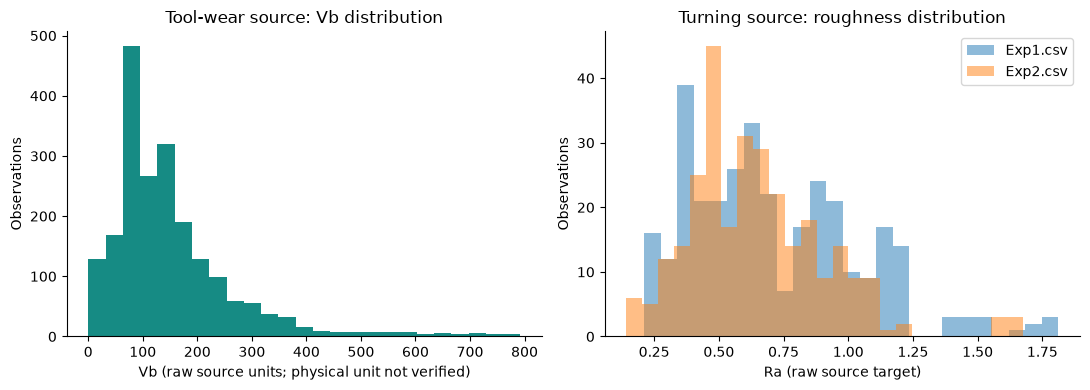

In [4]:
fig, ax = plt.subplots(1,2,figsize=(11,4))
pd.to_numeric(frames["tool_wear"]["Vb"],errors="coerce").dropna().plot.hist(bins=25,ax=ax[0],color="#168b84")
ax[0].set(title="Tool-wear source: Vb distribution",xlabel="Vb (raw source units; physical unit not verified)",ylabel="Observations")
for filename, group in frames["turning_roughness"].groupby("_source_file"):
    pd.to_numeric(group.Ra,errors="coerce").dropna().plot.hist(bins=25,alpha=.5,ax=ax[1],label=filename)
ax[1].set(title="Turning source: roughness distribution",xlabel="Ra (raw source target)",ylabel="Observations");ax[1].legend()
fig.tight_layout();plt.show()

## 3. Leakage and invalid-value checks
CycleToFailureNormalized is a transformation of the prediction target and must be excluded from a model predicting CycleToFailure. IDs and sequence fields are not predictive evidence by themselves. This notebook does not claim a trained or validated ML model.

In [5]:
life = frames["milling_life"]
print("Exclude from predictors:", [c for c in ["CycleToFailure", "CycleToFailureNormalized", "FileName", "SampleIndex"] if c in life])
print("Rows with non-numeric/missing tool-life target:", int(pd.to_numeric(life["CycleToFailure"],errors="coerce").isna().sum()))
print("Rows with non-numeric/missing Vb:", int(pd.to_numeric(frames["tool_wear"].Vb,errors="coerce").isna().sum()))
print("No rows were removed and no missing values were filled.")

Exclude from predictors: ['CycleToFailure', 'CycleToFailureNormalized', 'FileName', 'SampleIndex']
Rows with non-numeric/missing tool-life target: 0
Rows with non-numeric/missing Vb: 0
No rows were removed and no missing values were filled.


## 4. Actual MySQL operational snapshot
This is the same latest-reading view imported by the saved Power BI report. We count each machine once and preserve sensor names, units, status, quality and source provenance. Research-table counts show whether CSV data is actually loaded in MySQL; absence/zero is not an ingestion success.

In [6]:
snapshot, mysql_research_tables = mysql_snapshot()
assert not snapshot.empty, "MySQL latest-reading view is empty"
checks = reconciliation(snapshot)
assert checks["duplicate_machine_sensor_keys"] == 0
assert checks["missing_reading_ids"] == 0
display(pd.DataFrame([checks]))
display(mysql_research_tables)
display(snapshot.groupby(["data_source","data_provenance","data_quality"],dropna=False).size().rename("rows").reset_index())
print("Readings range:", str(snapshot.reading_timestamp.min()), "to", str(snapshot.reading_timestamp.max()))

,rows,machines,duplicate_machine_sensor_keys,missing_reading_ids,snapshot_sha256
0,1280,40,0,0,c9b4a2f7ddf5c730517aed644b0e54cb5e825a2af1a823...


,table,rows,present
0,raw_cnc_tool_wear,0,True
1,raw_turning_roughness,0,True
2,raw_mill_telemetry,0,True
3,raw_milling_cycles,0,True


,data_source,data_provenance,data_quality,rows
0,AI_SIMULATOR,SIMULATED,GOOD,1280


Readings range: 2026-11-03 05:21:19.020183 to 2026-11-03 05:21:25.377792


In [7]:
stats = live_statistics(snapshot)
display(stats)
invalid = snapshot.loc[~snapshot.valid_numeric]
print("Excluded from numeric statistics (non-GOOD or invalid):", len(invalid))
bounded = snapshot.loc[snapshot.valid_numeric & snapshot.expected_min.notna() & snapshot.expected_max.notna()].copy()
bounded["outside_expected"] = (bounded.numeric_value < bounded.expected_min) | (bounded.numeric_value > bounded.expected_max)
display(bounded.groupby(["sensor_name","sensor_unit"]).outside_expected.agg(["count","sum"]).rename(columns={"sum":"outside_expected_count"}).reset_index())

,sensor_name,sensor_unit,count,mean,median,min,max,std
0,Coolant Flow,L/min,40,25.054000,25.145000,24.250000,26.120000,0.435489
1,Coolant Temperature,°C,40,26.479750,26.485000,26.320000,26.600000,0.077111
2,Current,A,40,70.256000,70.330000,66.840000,74.070000,1.512300
3,Cycle Time,s/cycle,40,360.000000,360.000000,360.000000,360.000000,0.000000
4,Good Parts,parts,40,167.525000,167.500000,162.000000,171.000000,2.099908
5,Model Down Time,s,40,10755.975200,10765.161500,10587.474000,10830.469000,51.377725
6,Model Downtime Hour Cost,INR/h,40,1200.000000,1200.000000,1200.000000,1200.000000,0.000000
7,Model Downtime Loss,INR,40,3581.229083,3583.701667,3522.469667,3605.046333,18.086083
8,Model Electrical Energy,kWh,40,428.292624,428.856356,421.550637,430.449842,1.973390
9,Model Electrical Power,kW,40,29.777222,29.883333,28.700000,30.511111,0.402461


Excluded from numeric statistics (non-GOOD or invalid): 0


,sensor_name,sensor_unit,count,outside_expected_count
0,Coolant Flow,L/min,40,0
1,Coolant Temperature,°C,40,0
2,Current,A,40,0
3,Cycle Time,s/cycle,40,0
4,Good Parts,parts,40,40
5,Model Down Time,s,40,0
6,Model Downtime Hour Cost,INR/h,40,0
7,Model Downtime Loss,INR,40,0
8,Model Electrical Energy,kWh,40,0
9,Model Electrical Power,kW,40,0


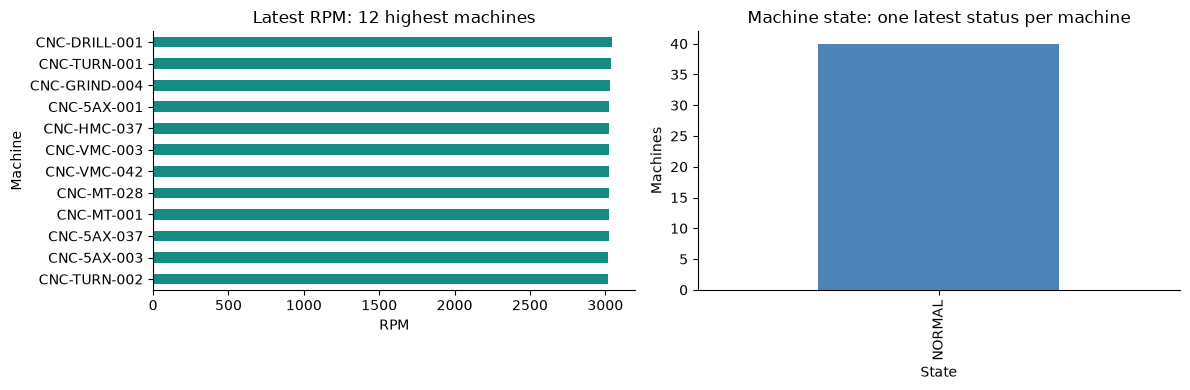

In [8]:
rpm = snapshot.loc[snapshot.valid_numeric & snapshot.sensor_name.eq("RPM") & snapshot.sensor_unit.eq("RPM")].sort_values("numeric_value",ascending=False)
fig, axes = plt.subplots(1,2,figsize=(12,4))
rpm.head(12).plot.barh(x="machine_code",y="numeric_value",ax=axes[0],color="#168b84",legend=False)
axes[0].invert_yaxis();axes[0].set(title="Latest RPM: 12 highest machines",xlabel="RPM",ylabel="Machine")
status = snapshot.sort_values("reading_timestamp").drop_duplicates("machine_id",keep="last").machine_status.value_counts()
status.plot.bar(ax=axes[1],color="#4e83b8");axes[1].set(title="Machine state: one latest status per machine",xlabel="State",ylabel="Machines")
fig.tight_layout();plt.show()

## 5. Independent reconciliation and saved evidence
A second computation using Python standard-library statistics checks the pandas results. The evidence export records the exact snapshot hash, inputs and execution time. It contains sensor data only, no users or secrets. Statistics from different moments need not match a later live refresh.

In [9]:
import statistics
for row in stats.to_dict("records"):
    values = snapshot.loc[snapshot.valid_numeric & snapshot.sensor_name.eq(row["sensor_name"]) & snapshot.sensor_unit.eq(row["sensor_unit"]),"numeric_value"].tolist()
    assert len(values) == row["count"]
    assert np.isclose(statistics.mean(values), row["mean"])
    assert np.isclose(statistics.median(values), row["median"])
    if len(values)>1: assert np.isclose(statistics.stdev(values),row["std"])
out = ROOT / "reports" / "phase1"
out.mkdir(parents=True,exist_ok=True)
snapshot.to_csv(out/"mysql_latest_snapshot.csv",index=False)
stats.to_csv(out/"mysql_sensor_statistics.csv",index=False)
manifest.to_csv(out/"research_source_manifest.csv",index=False)
evidence = {"executed_at_utc":executed_at,"source":"FactoryPulse MySQL latest view + original local CSV files","snapshot":checks,"research_quality":quality.to_dict("records"),"research_statistics":research_stats,"mysql_research_tables":mysql_research_tables.to_dict("records"),"independent_statistics_match":True,"database_writes":False,"limits":["Operational readings are simulator-generated","Latest view is not history","No trained ML model","MTBF and financial rates are not inferred"]}
(out/"notebook_evidence.json").write_text(json.dumps(evidence,indent=2,default=str),encoding="utf-8")
print("Independent statistics checks passed; evidence saved to reports/phase1.")

Independent statistics checks passed; evidence saved to reports/phase1.


## Interpretation and limits
The saved outputs prove this execution against identified sources. They do not certify industrial equipment, business costs or production accounting. Latest snapshots show fleet comparisons, not historical OEE. Non-GOOD values are excluded from arithmetic, not deleted from storage. Cumulative production counters must use reset-aware deltas over a defined shift, never sums of samples. MySQL remains the operational source of truth; no Supabase query proxy is involved.